# Land processes: snow storage and melt

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/29-land.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/29-land.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `e736c941b7bd21ace757dd25adcb0013c373f2b861f108c7eb8d4681d14703db`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Land processes: snow storage and melt

**Lesson 29 · Original synthetic data · Independent educational project**

## Objectives

Partition precipitation; track snow storage; close a water budget.

[Previous](28-regional-extremes.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/29-land.ipynb) · [Next](30-waves.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=29-land.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

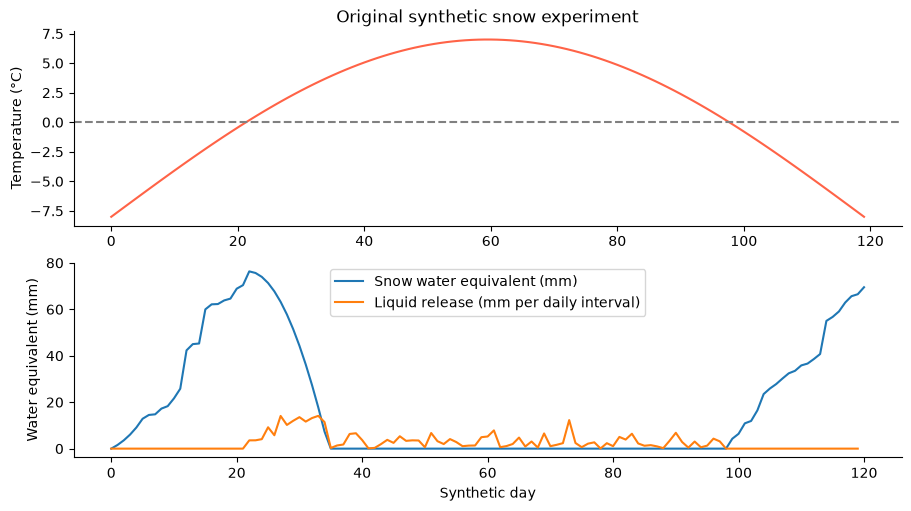

Input 377.14 mm; liquid 307.62 mm; final snow 69.51 mm


In [2]:
rng = np.random.default_rng(29)
day = np.arange(120)
temperature = -8 + 15*np.sin(np.pi*day/119)
precipitation = rng.gamma(1.5, 2, len(day))
snowfall = np.where(temperature < 0, precipitation, 0)
rain = precipitation - snowfall
snow = np.zeros(len(day)+1)
melt = np.zeros(len(day))
for i in range(len(day)):
    available = snow[i] + snowfall[i]
    # A chosen teaching coefficient: 3 mm per day per positive degree C.
    melt[i] = min(available, 3*max(temperature[i], 0))
    snow[i+1] = available - melt[i]
liquid = rain + melt
assert np.all(snow >= 0)
assert np.allclose(precipitation, liquid + np.diff(snow))
assert np.isclose(precipitation.sum(), liquid.sum()+snow[-1]-snow[0])
fig, axes = plt.subplots(2, 1, figsize=(9, 5), constrained_layout=True)
axes[0].plot(day, temperature, color="tomato")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(ylabel="Temperature (°C)", title="Original synthetic snow experiment")
axes[1].plot(np.arange(len(snow)), snow, label="Snow water equivalent (mm)")
axes[1].plot(day, liquid, label="Liquid release (mm per daily interval)")
axes[1].set(xlabel="Synthetic day", ylabel="Water equivalent (mm)")
axes[1].legend(); plt.show()
print(f"Input {precipitation.sum():.2f} mm; liquid {liquid.sum():.2f} mm; final snow {snow[-1]:.2f} mm")

## Exercise

Change the melt coefficient and the temperature sequence. Check the budget again, then compare the timing of liquid release with total water input.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

ECMWF's land ML component addresses land-surface processes. This original degree-day bucket illustrates one storage mechanism only: it omits soil, vegetation, radiation, sublimation and refreezing. Liquid release is not routed river discharge. The model is not aiLand or a trained ML emulator. Lesson 09 supplies a separate hydrological storage exercise, and lesson 27 introduces held-out ML validation.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/ml-earth-system-components/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).